# Wastewater vs cases: sensitivity analysis

Workflow (each step is its own cell, nothing is saved or run inside a function):

1. **Config**: edit `POP_SIZE`, `TEST_DELAY`, `MODEL_TYPE`, `SWEEPS`, etc.
2. **Simulate**: runs Covasim and returns the daily time series (burden, cases, wastewater) for every run. Slow, so do it once per (`POP_SIZE`, `TEST_DELAY`).
3. **Fit**: fits the cases / wastewater / both models on those time series (`"linear"` or `"rank"`). Fast, no re-simulation needed.
4. **Plot**.

To run `test_delay = 0`, `test_delay = 3`, linear and rank: simulate twice (delay 0 and delay 3), then fit each one with `MODEL_TYPE = "linear"` and `"rank"`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

import covasim as cv

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM


In [46]:
import time

In [6]:
from pathlib import Path
print(Path.cwd())                                          # the folder relative paths start from
print(sorted(p.name for p in Path("sensitivity_results").glob("*")) if Path("sensitivity_results").exists() else "no sensitivity_results folder here")

/storage/hcraddock/GitHub/covasim4wastewater/modeling/analysis_sandiego_cases_waste_water
['timeseries_pop10000_delay0.csv']


## Data extraction

In [2]:
def extract_wastewater_regression_data(sim) -> pd.DataFrame:
    """
    Extract daily (burden, cases, wastewater) from a Covasim sim that has been run.

    burden     -> new_infections   (true, unobserved disease burden)
    cases      -> new_diagnoses    (observed via testing/surveillance)
    wastewater -> sum of viral_shedding_hist across agents, per day

    `new_diagnoses` is all zeros unless the sim has a testing intervention.
    """
    results = sim.results

    burden = np.asarray(results['new_infections'].values, dtype=float)

    if 'new_diagnoses' not in results:
        raise KeyError("sim.results has no 'new_diagnoses' — did the sim run?")
    cases = np.asarray(results['new_diagnoses'].values, dtype=float)
    if cases.sum() == 0:
        print("Warning: 'cases' (new_diagnoses) is all zero. "
              "Add a testing intervention, e.g. cv.test_prob(...), to the sim.")

    viral_shedding_hist = np.asarray(results['viral_shedding_hist'])  # (n_people, n_days)
    wastewater = viral_shedding_hist.sum(axis=0)

    n = len(burden)
    return pd.DataFrame({
        'day': np.arange(n),
        'date': [sim.date(d) for d in range(n)],
        'burden': burden,
        'cases': cases,
        'wastewater': wastewater[:n],
    })

## 1. Config
Edit this cell, then run everything below it.

In [7]:
# ---- Simulation settings (changing these means re-simulating) -------------
POP_SIZE      = 10000
POP_INFECTED  = int(POP_SIZE * 0.0016)   # ~0.16% of the population (16 per 10,000)
N_DAYS        = 120
N_RUNS        = 100                      # random seeds per parameter setting
CHUNK_SIZE    = 10                       # sims held in memory at once (100k-agent sims are big)
RAND_SEED     = 1

TEST_DELAY    = 0                        # <-- fixed testing delay (days) for the symp_prob sweep
BASELINE      = dict(symp_prob=0.03, asymp_prob=0.002, test_delay=TEST_DELAY)
ISO_FACTOR    = dict(h=0.4, s=0.1, w=0.1, c=0.1)   # constant in every simulation

# One-at-a-time sweeps (the swept value overrides BASELINE)
SWEEPS = {
    "symp_prob": [0.01, 0.03, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35],
    # "asymp_prob": [0.0, 0.002, 0.01, 0.05],
    # "test_delay": [1, 3, 7, 10],
}

# ---- Analysis settings (changing these does NOT need re-simulation) --------
MODEL_TYPE       = "linear"                   # "linear" or "rank"
FIZZLE_THRESHOLD = 0.01 * POP_SIZE            # skip runs where <1% of the population was ever infected
BAND             = "iqr"                      # "iqr" or "ci"

# ---- Output locations / names ----------------------------------------------
OUT_DIR  = Path("sensitivity_results")
SIM_TAG  = f"pop{POP_SIZE}_delay{TEST_DELAY}"      # names the simulation files
FIT_TAG  = f"{SIM_TAG}_{MODEL_TYPE}"               # names the fit/plot files
print("SIM_TAG:", SIM_TAG, "| FIT_TAG:", FIT_TAG)

SIM_TAG: pop10000_delay0 | FIT_TAG: pop10000_delay0_linear


## Functions
These only compute and return things. They don't read config globals or write files.

In [23]:
def build_sim(pop_size, pop_infected, n_days, test_kwargs, iso_factor, rand_seed):
    """Build one Covasim sim with a test_prob intervention."""
    return cv.Sim(
        pop_size=pop_size,
        pop_type='hybrid',
        pop_infected=pop_infected,
        location='zambia',
        n_days=n_days,
        n_imports=0,
        interventions=[cv.test_prob(**test_kwargs)],
        iso_factor=iso_factor,
        rand_seed=rand_seed,
        verbose=0,
    )


def simulate_setting(param_name, param_value, baseline, n_runs, chunk_size,
                     pop_size, pop_infected, n_days, iso_factor, rand_seed):
    """Run n_runs stochastic sims at one parameter setting (others at baseline).
    Returns a long DataFrame of daily time series: param, value, run, day, burden, cases, wastewater.
    Sims run in chunks and are discarded after extraction to keep memory bounded."""
    test_kwargs = dict(baseline)
    test_kwargs[param_name] = param_value

    frames = []
    for start in range(0, n_runs, chunk_size):
        k = min(chunk_size, n_runs - start)
        base_sim = build_sim(pop_size, pop_infected, n_days, test_kwargs, iso_factor,
                             rand_seed=rand_seed + start)
        msim = cv.MultiSim(base_sim, n_runs=k)
        msim.run()
        for i, sim in enumerate(msim.sims):
            df = extract_wastewater_regression_data(sim)[['day', 'burden', 'cases', 'wastewater']]
            df.insert(0, 'run', start + i)
            frames.append(df)
        del msim
    out = pd.concat(frames, ignore_index=True)
    out.insert(0, 'value', param_value)
    out.insert(0, 'param', param_name)
    return out


def simulate_sweeps(sweeps, **kwargs):
    """Run simulate_setting for every (param, value) in sweeps; return one concatenated DataFrame."""
    frames = []
    for param_name, values in sweeps.items():
        for value in values:
            print(f"Simulating {param_name} = {value} ...")
            frames.append(simulate_setting(param_name, value, **kwargs))
    return pd.concat(frames, ignore_index=True)


def fit_models(timeseries, model_type="linear", fizzle_threshold=0.0):
    """Fit cases / wastewater / both models on each run's time series.
    model_type 'linear': OLS on the raw values.
    model_type 'rank'  : OLS on the ranks of burden, cases and wastewater (Spearman-style).
    Returns one row per run."""
    if model_type not in ("linear", "rank"):
        raise ValueError("model_type must be 'linear' or 'rank'")

    rows = []
    for (param, value, run), df in timeseries.groupby(['param', 'value', 'run'], sort=False):
        fizzled = df['burden'].sum() < fizzle_threshold
        row = dict(param=param, value=value, run=run, fizzled=fizzled)
        if not fizzled:
            d = df[['burden', 'cases', 'wastewater']]
            if model_type == "rank":
                d = d.rank()
            m_cases = smf.ols('burden ~ cases', data=d).fit()
            m_ww    = smf.ols('burden ~ wastewater', data=d).fit()
            m_both  = smf.ols('burden ~ cases + wastewater', data=d).fit()
            row.update(
                adjr2_cases=m_cases.rsquared_adj,
                adjr2_wastewater=m_ww.rsquared_adj,
                adjr2_both=m_both.rsquared_adj,
                p_add_ww=anova_lm(m_cases, m_both)['Pr(>F)'].iloc[1],     # wastewater adds value beyond cases?
                p_add_cases=anova_lm(m_ww, m_both)['Pr(>F)'].iloc[1],     # cases adds value beyond wastewater?
            )
        rows.append(row)
    return pd.DataFrame(rows)


def summarize(per_run, n_boot=2000, seed=0):
    """Collapse per-run fits to one row per (param, value): median, IQR, bootstrap 95% CI of the median."""
    rng = np.random.default_rng(seed)
    out = []
    for (param, value), g in per_run.groupby(['param', 'value'], sort=False):
        used = g[~g['fizzled']]
        row = dict(param=param, value=value, n_used=len(used), n_fizzled=int(g['fizzled'].sum()))
        for name in ("cases", "wastewater", "both"):
            x = used[f"adjr2_{name}"].to_numpy(dtype=float)
            if len(x):
                boot = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
                row[f"median_AdjR2_{name}"] = np.median(x)
                row[f"q25_{name}"], row[f"q75_{name}"] = np.percentile(x, [25, 75])
                row[f"ci_low_{name}"], row[f"ci_high_{name}"] = np.percentile(boot, [2.5, 97.5])
                row[f"mean_{name}"] = x.mean()
                row[f"sd_{name}"] = x.std(ddof=1) if len(x) > 1 else np.nan
            else:
                row.update({f"median_AdjR2_{name}": np.nan, f"q25_{name}": np.nan, f"q75_{name}": np.nan,
                            f"ci_low_{name}": np.nan, f"ci_high_{name}": np.nan})
        row["pct_ww_helps"]    = (used["p_add_ww"] < 0.05).mean() * 100 if len(used) else np.nan
        row["pct_cases_helps"] = (used["p_add_cases"] < 0.05).mean() * 100 if len(used) else np.nan
        out.append(row)
    return pd.DataFrame(out)

## 2. Simulate
The slow step. Only re-run when `POP_SIZE`, `TEST_DELAY`, `N_RUNS`, `SWEEPS` etc. change.

In [ ]:
timeseries = simulate_sweeps(
    SWEEPS,
    baseline=BASELINE, n_runs=N_RUNS, chunk_size=CHUNK_SIZE,
    pop_size=POP_SIZE, pop_infected=POP_INFECTED, n_days=N_DAYS,
    iso_factor=ISO_FACTOR, rand_seed=RAND_SEED,
)
timeseries.head()

### Save simulations

In [ ]:
OUT_DIR.mkdir(exist_ok=True)
timeseries.to_csv(OUT_DIR / f"timeseries_{SIM_TAG}.csv", index=False)
print("Saved", OUT_DIR / f"timeseries_{SIM_TAG}.csv")

### (Optional) Load previously saved simulations instead of re-running
Set `SIM_TAG` in the config cell to the sims you want, then run this.

In [8]:
timeseries = pd.read_csv(OUT_DIR / f"timeseries_{SIM_TAG}.csv")
timeseries.head()

,param,value,run,day,burden,cases,wastewater
0,symp_prob,0.01,0,0,0.0,0.0,0.00
1,symp_prob,0.01,0,1,0.0,0.0,0.00
2,symp_prob,0.01,0,2,0.0,0.0,0.00
3,symp_prob,0.01,0,3,1.0,0.0,288454.03
4,symp_prob,0.01,0,4,5.0,0.0,580048.56


## 3. Fit models
Set `MODEL_TYPE` in the config cell (`"linear"` or `"rank"`) and re-run from here down. No re-simulation.

In [ ]:
per_run = fit_models(timeseries, model_type=MODEL_TYPE, fizzle_threshold=FIZZLE_THRESHOLD)
results = summarize(per_run)
results.round(3)

,param,value,n_used,n_fizzled,median_AdjR2_cases,q25_cases,q75_cases,ci_low_cases,ci_high_cases,median_AdjR2_wastewater,...,q75_wastewater,ci_low_wastewater,ci_high_wastewater,median_AdjR2_both,q25_both,q75_both,ci_low_both,ci_high_both,pct_ww_helps,pct_cases_helps
0,symp_prob,0.01,100,0,0.584,0.557,0.610,0.570,0.597,0.807,...,0.812,0.804,0.808,0.822,0.812,0.830,0.820,0.826,100.0,86.000
1,symp_prob,0.03,100,0,0.660,0.637,0.687,0.653,0.666,0.812,...,0.817,0.809,0.814,0.836,0.829,0.845,0.832,0.839,100.0,97.000
2,symp_prob,0.10,100,0,0.735,0.722,0.753,0.730,0.743,0.825,...,0.831,0.823,0.827,0.845,0.835,0.852,0.840,0.848,100.0,92.000
3,symp_prob,0.15,100,0,0.763,0.746,0.775,0.757,0.767,0.832,...,0.837,0.829,0.834,0.842,0.836,0.850,0.840,0.846,100.0,80.000
4,symp_prob,0.20,100,0,0.787,0.774,0.798,0.783,0.791,0.836,...,0.844,0.833,0.838,0.839,0.832,0.845,0.837,0.841,100.0,42.000
5,symp_prob,0.25,100,0,0.799,0.789,0.812,0.796,0.803,0.842,...,0.851,0.839,0.844,0.842,0.836,0.851,0.839,0.846,100.0,14.000
6,symp_prob,0.30,100,0,0.810,0.798,0.826,0.806,0.814,0.842,...,0.854,0.841,0.847,0.843,0.835,0.854,0.841,0.847,100.0,6.000
7,symp_prob,0.35,98,2,0.821,0.809,0.839,0.818,0.828,0.847,...,0.860,0.843,0.851,0.848,0.839,0.863,0.844,0.853,100.0,14.286


In [ ]:
OUT_DIR.mkdir(exist_ok=True)
per_run.to_csv(OUT_DIR / f"per_run_{FIT_TAG}.csv", index=False)
results.to_csv(OUT_DIR / f"summary_{FIT_TAG}.csv", index=False)
print("Saved", OUT_DIR / f"summary_{FIT_TAG}.csv")

## 4. Plot

In [86]:
STYLES = [   # model, legend label, line colour, band colour, line style, marker
    ("cases",      "Reported Cases only",      "black",          "black",          "-",  "o"),
    #("wastewater", "Wastewater only", "cornflowerblue", "cornflowerblue", "-",  "s"),
    #("both",       "Reported Cases & Wastewater",            "cornflowerblue",       "cornflowerblue",        "--", "^"),
    ("both",       "Reported Cases & Wastewater",            BLUE,      BLUE,        "--", "^")
]

BAND_LABEL = {"iqr": "Interquartile range across runs", "ci": "95% CI of the median (bootstrap)"}

def draw_adjr2(ax, results, param, band="iqr", fs=14, legend_fs=16, show=("cases", "both")):
    sub = results[results["param"] == param].sort_values("value")
    x = sub["value"].astype(float)
    lo, hi = ("q25", "q75") if band == "iqr" else ("ci_low", "ci_high")
    for name, label, color, band_color, ls, mk in STYLES:
        if name not in show:
            continue
        ax.fill_between(x, sub[f"{lo}_{name}"], sub[f"{hi}_{name}"], color=band_color,
                        alpha=0.20 if name == "both" else 0.15, linewidth=0)
        ax.plot(x, sub[f"median_AdjR2_{name}"], ls=ls, marker=mk, color=color, lw=3, ms=10,
                label=label, clip_on=False)
    ax.set_xlim(left=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
    handles, labels = ax.get_legend_handles_labels()
    #handles.append(Patch(facecolor="gray", alpha=0.25, label=BAND_LABEL[band]))
    ax.legend(handles=handles, fontsize=legend_fs, loc="lower right", frameon=False)

def plot_symp_prob(results, band="iqr", title=None):
    """Returns the figure; does not save."""
    fig, ax = plt.subplots(figsize=(9.2, 6.9))
    draw_adjr2(ax, results, "symp_prob", band)
    ax.set_xlabel("Symptomatic testing probability (per day)", fontsize=17)
    ax.set_ylabel("Median adjusted R\u00b2 across simulated outbreaks", fontsize=16)
    ax.tick_params(labelsize=14)
    if title:
        ax.set_title(title, fontsize=16)
    fig.tight_layout()
    return fig

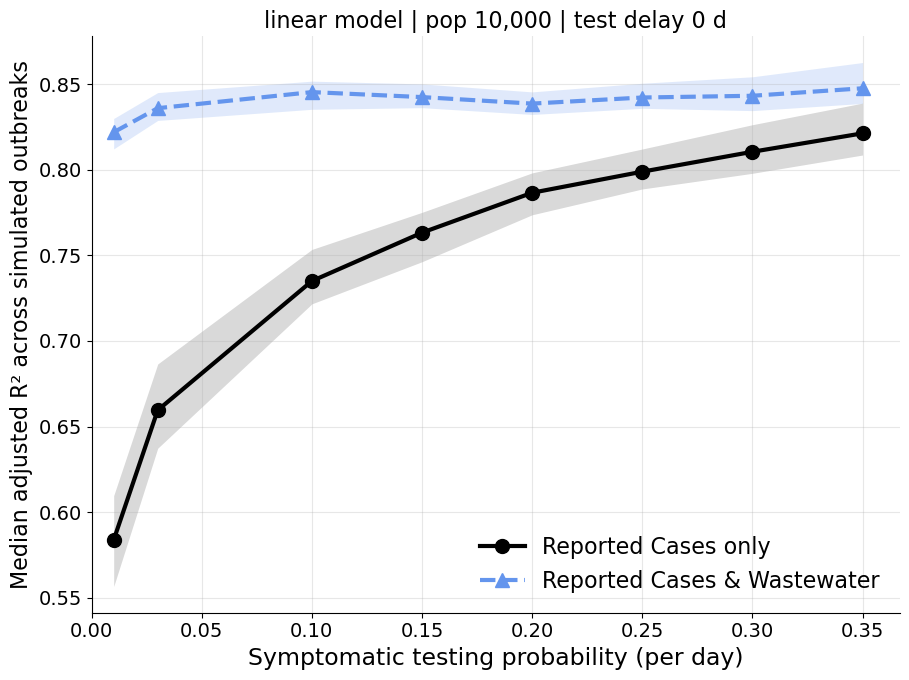

In [28]:
fig = plot_symp_prob(
    results, band=BAND,
    title=f"{MODEL_TYPE} model | pop {POP_SIZE:,} | test delay {TEST_DELAY} d",
)
plt.show()

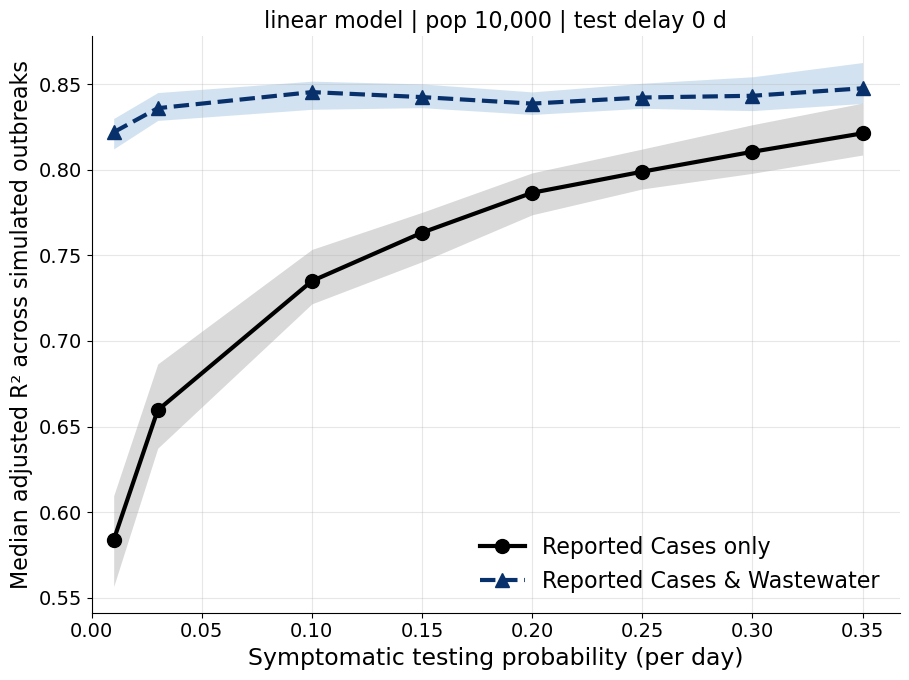

In [20]:
fig = plot_symp_prob(
    results, 
    title=f"{MODEL_TYPE} model | pop {POP_SIZE:,} | test delay {TEST_DELAY} d",
)
plt.show()

In [ ]:
fig.savefig(OUT_DIR / f"sensitivity_symp_prob_adjR2_{FIT_TAG}.png", dpi=200)
print("Saved", OUT_DIR / f"sensitivity_symp_prob_adjR2_{FIT_TAG}.png")

### Error bar plot

In [85]:
BLUE = "#224e95"

In [81]:
from matplotlib.lines import Line2D

def draw_adjr2_sd(ax, res, param="symp_prob", legend_fs=16, offset=0.004):
    sub = res[res["param"] == param].sort_values("value")
    x = sub["value"].astype(float).to_numpy()
    n = len(STYLES)
    for k, (name, label, color, band_color, ls, mk) in enumerate(STYLES):
        dx = (k - (n - 1) / 2) * offset            # small horizontal nudge so the bars don't overlap
        ax.errorbar(x + dx, sub[f"mean_{name}"], yerr=sub[f"sd_{name}"], color=color, ls=ls, marker=mk,
                    lw=3, ms=10, capsize=4, elinewidth=1.8, label=label, clip_on=False)
    ax.set_xlim(left=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Line2D([0], [0], color="gray", marker="_", ls="none", markersize=14, label="Error bars: \u00b1 SD across runs"))
    leg = ax.legend(handles=handles, fontsize=legend_fs, loc="lower right", frameon=False)
    leg.get_texts()[-1].set_fontsize(10)        # only the "Error bars: ± SD across runs" entry

def plot_symp_prob_sd(res, title=None):
    fig, ax = plt.subplots(figsize=(9.2, 6.9))
    draw_adjr2_sd(ax, res)
    ax.set_xlabel("Symptomatic testing probability (per day)", fontsize=17)
    ax.set_ylabel("Mean adjusted R\u00b2 across simulated outbreaks", fontsize=16)
    ax.set_title(f"Reported Cases: Varying the Symptomatic Testing Probability", fontsize=16)
    ax.tick_params(labelsize=14)
    if title:
        ax.set_title(title, fontsize=16)
    fig.tight_layout()
    return fig

In [ ]:
fig2 = plot_symp_prob_sd(results["linear"])     # or results["rank"]

In [24]:
per_run2 = fit_models(timeseries, model_type=MODEL_TYPE, fizzle_threshold=FIZZLE_THRESHOLD)
results2 = summarize(per_run2)
results2.round(3)

,param,value,n_used,n_fizzled,median_AdjR2_cases,q25_cases,q75_cases,ci_low_cases,ci_high_cases,mean_cases,...,sd_wastewater,median_AdjR2_both,q25_both,q75_both,ci_low_both,ci_high_both,mean_both,sd_both,pct_ww_helps,pct_cases_helps
0,symp_prob,0.01,100,0,0.584,0.557,0.610,0.570,0.597,0.582,...,0.010,0.822,0.812,0.830,0.820,0.826,0.822,0.012,100.0,86.000
1,symp_prob,0.03,100,0,0.660,0.637,0.687,0.653,0.666,0.662,...,0.010,0.836,0.829,0.845,0.832,0.839,0.837,0.013,100.0,97.000
2,symp_prob,0.10,100,0,0.735,0.722,0.753,0.730,0.743,0.737,...,0.010,0.845,0.835,0.852,0.840,0.848,0.844,0.012,100.0,92.000
3,symp_prob,0.15,100,0,0.763,0.746,0.775,0.757,0.767,0.762,...,0.010,0.842,0.836,0.850,0.840,0.846,0.843,0.011,100.0,80.000
4,symp_prob,0.20,100,0,0.787,0.774,0.798,0.783,0.791,0.787,...,0.013,0.839,0.832,0.845,0.837,0.841,0.841,0.013,100.0,42.000
5,symp_prob,0.25,100,0,0.799,0.789,0.812,0.796,0.803,0.801,...,0.016,0.842,0.836,0.851,0.839,0.846,0.845,0.017,100.0,14.000
6,symp_prob,0.30,100,0,0.810,0.798,0.826,0.806,0.814,0.814,...,0.022,0.843,0.835,0.854,0.841,0.847,0.848,0.022,100.0,6.000
7,symp_prob,0.35,98,2,0.821,0.809,0.839,0.818,0.828,0.826,...,0.024,0.848,0.839,0.863,0.844,0.853,0.854,0.024,100.0,14.286


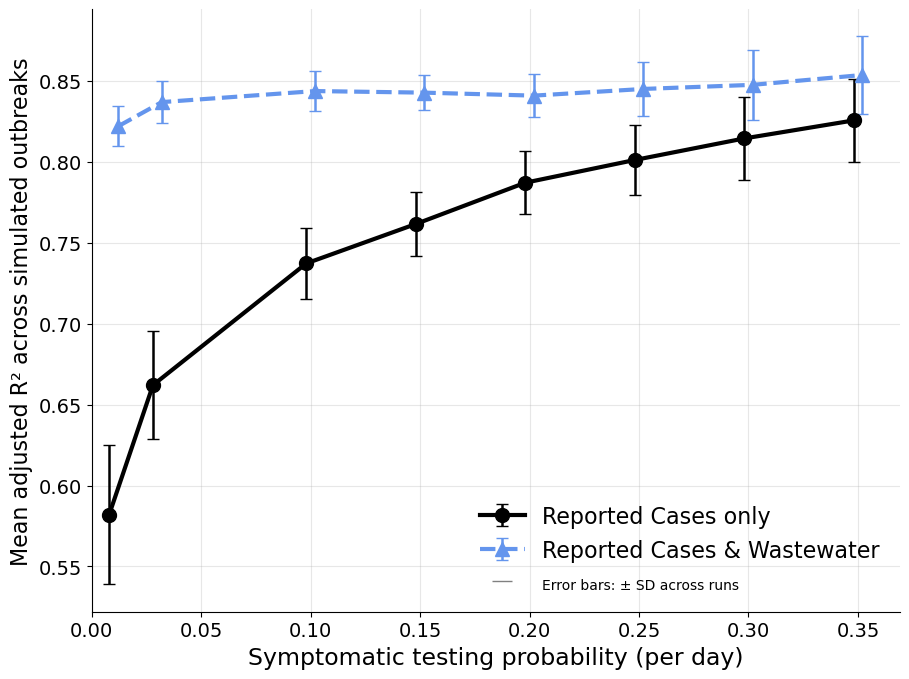

In [37]:
fig2 = plot_symp_prob_sd(results2)     # or results["rank"]

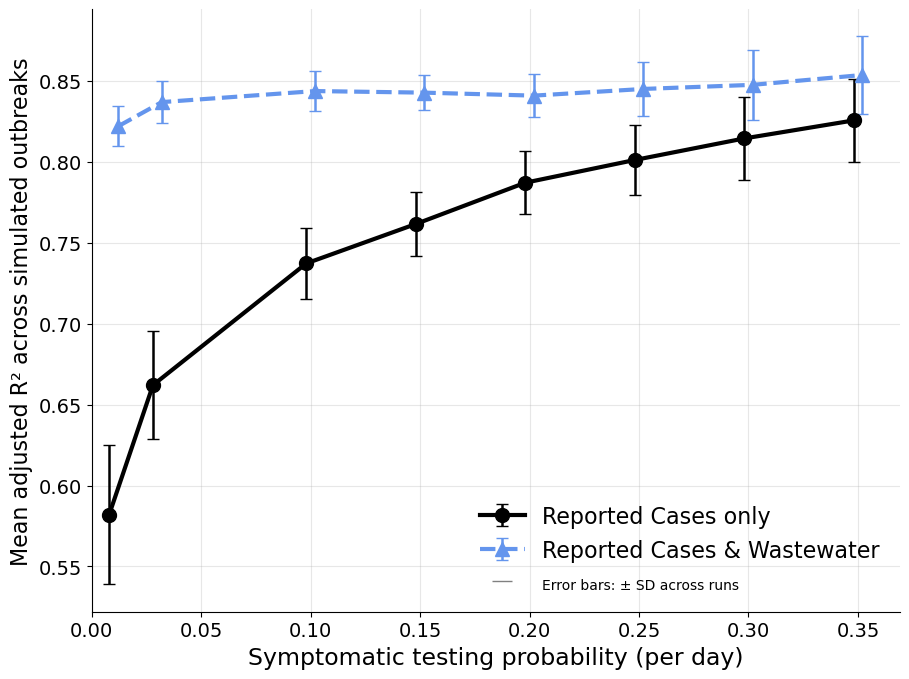

In [60]:
fig2 = plot_symp_prob_sd(results2)    

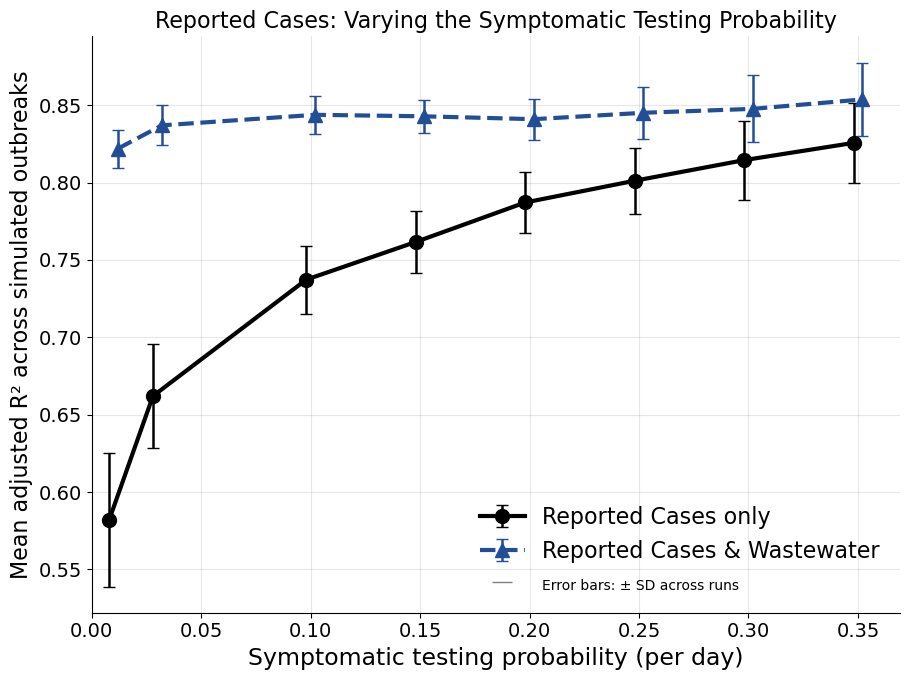

In [87]:
fig2 = plot_symp_prob_sd(results2)    

## Part 2: Waste-water Data

In [40]:
one = timeseries[(timeseries["param"] == "symp_prob") & (timeseries["value"] == 0.10) & (timeseries["run"] == 0)]

In [42]:
from matplotlib.lines import Line2D

In [43]:
SAMPLING_EVERY = [1, 3, 5, 7, 14]    # days between wastewater samples (1 = daily, untouched)
WINDOWS = [1, 3]                     # trailing average over the last N samples (1 = last sample carried forward)
SAMPLING_SYMP_PROBS = [0.10]         # testing level(s), one panel each
MODEL = "linear"                     # "linear" or "rank"

In [ ]:
def thin_wastewater(df, every, window_samples, offset=0):
    """Keep wastewater only every `every`-th day starting on day `offset`, then give each day the average of the
    samples in the TRAILING window of window_samples*every days (only past/current samples: no leakage)."""
    out = df.copy()
    if every > 1:
        s = pd.Series(np.nan, index=out.index)
        keep = np.arange(offset, len(out), every)
        s.iloc[keep] = out["wastewater"].to_numpy(float)[keep]
        out["wastewater"] = s.rolling(window_samples * every, min_periods=1).mean()
    return out[out["day"] >= FIRST_DAY]

ts_s = timeseries[(timeseries["param"] == "symp_prob") &
                  np.isclose(timeseries["value"].astype(float).to_numpy()[:, None], SAMPLING_SYMP_PROBS).any(axis=1)]
groups = [d.sort_values("day") for _, d in ts_s.groupby(["param", "value", "run"], sort=False)]

In [ ]:
FIRST_ANALYSIS_DAY = max(SAMPLING_EVERY) - 1    # days before this are dropped, so every run and every sampling scheme
                                                # is compared on the same days (and every day has a past sample to use)

def sample_wastewater_sparsely(daily_run, days_between_samples, n_samples_averaged,
                               first_sample_day=0, analysis_start_day=FIRST_ANALYSIS_DAY):
    """
    Turn ONE simulated run's daily wastewater series into what a sparse sampling programme would report.

    1. A sample is taken only every `days_between_samples` days, starting on `first_sample_day`.
       On all other days there is no measurement.
    2. Every day is then given a value: the average of the samples inside a BACKWARD-looking window that ends
       on that day and is (n_samples_averaged * days_between_samples) days long. That window holds the last
       `n_samples_averaged` samples (including today's, if today is a sample day). Nothing after the day is used,
       so there is no leakage from the future. With n_samples_averaged = 1 this is simply "carry the latest
       sample forward". Early in a run fewer samples exist, so it averages whatever is available.
    3. Days before `analysis_start_day` are dropped.

    days_between_samples = 1 means daily wastewater: the series is left untouched (apart from step 3).

    Args:
        daily_run:            DataFrame for one run, one row per day, sorted by day, with a `wastewater` column.
        days_between_samples: gap between samples in days (1 = daily).
        n_samples_averaged:   how many of the latest samples are averaged (1 = last sample carried forward).
        first_sample_day:     which day the first sample is taken (vary it between runs so no sampling schedule
                              is favoured).
        analysis_start_day:   first day kept for the regressions.

    Returns:
        A copy of daily_run with `wastewater` replaced by the sparsely sampled, averaged series.
    """
    result = daily_run.copy()

    if days_between_samples > 1:
        
        # row numbers of the days on which a sample is taken
        sample_positions = np.arange(first_sample_day, len(result), days_between_samples)

        # wastewater on sample days; NaN (= no measurement) on every other day
        measured = pd.Series(np.nan, index=result.index)
        measured.iloc[sample_positions] = result["wastewater"].to_numpy(float)[sample_positions]

        # length of the backward-looking window, in days
        window_days = n_samples_averaged * days_between_samples

        # average of the samples inside the window (NaNs are ignored)
        result["wastewater"] = measured.rolling(window_days, min_periods=1).mean()

    return result[result["day"] >= analysis_start_day]


# the runs to analyse: only the chosen testing probabilities
selected_runs = timeseries[(timeseries["param"] == "symp_prob") &
                           np.isclose(timeseries["value"].astype(float).to_numpy()[:, None], SAMPLING_SYMP_PROBS).any(axis=1)]

# one DataFrame per simulated run (rows = days), kept in a list
runs_daily = [run_df.sort_values("day") for _, run_df in selected_runs.groupby(["param", "value", "run"], sort=False)]

In [ ]:
##EXPLAIN
    # days_between_samples == 1 means a sample every day, i.e. the daily series is already what the programme
    # would report, so there is nothing to thin out or average.
    if days_between_samples > 1:

        # Which days a sample is taken on: first_sample_day, then every days_between_samples days after it.
        # These are row numbers, and they equal day numbers because each run has one row per day starting at
        # day 0. Example: first_sample_day = 2 and days_between_samples = 7 give days 2, 9, 16, 23, ...
        sample_positions = np.arange(first_sample_day, len(result), days_between_samples)

        # Build the series the programme would actually have: the true wastewater value on sample days,
        # and NaN ("no measurement") on every other day. Using result.index keeps this aligned row by row
        # with the original data.
        measured = pd.Series(np.nan, index=result.index)
        measured.iloc[sample_positions] = result["wastewater"].to_numpy(float)[sample_positions]

        # Length of the backward-looking window, in days. Samples are days_between_samples apart, so a window of
        # n_samples_averaged * days_between_samples days always spans exactly n_samples_averaged samples.
        # Example: samples every 7 days with 3 samples averaged gives a 21-day window.
        window_days = n_samples_averaged * days_between_samples

        # Replace the daily wastewater with what would be known on each day: the

In [ ]:
#SIMULATION
FIRST_DAY = max(SAMPLING_EVERY) - 1  # every fit uses days >= this, so all runs/intervals use the same rows and no day lacks a past sample
rng = np.random.default_rng(0)

fits = []
for win in WINDOWS:
    for every in SAMPLING_EVERY:
        if every == 1 and win != WINDOWS[0]:
            continue                                   # daily data is untouched, so one fit covers every window
        t0 = time.time()
        parts = [thin_wastewater(d, every, win, offset=int(rng.integers(0, every))) for d in groups]   # random sampling start per run
        f = fit_models(pd.concat(parts, ignore_index=True), model_type=MODEL, fizzle_threshold=FIZZLE_THRESHOLD)
        f["every"], f["window"] = every, win
        fits.append(f)
        print(f"window {win}, every {every} day(s): {time.time() - t0:.0f} s", flush=True)
per_run_s = pd.concat(fits, ignore_index=True)

used = per_run_s[~per_run_s["fizzled"].astype(bool)]
rows = []
for (v, win, every), g in used.groupby(["value", "window", "every"]):
    rows.append(dict(value=v, window=win, every=every,
                     mean_cases=g["adjr2_cases"].mean(), sd_cases=g["adjr2_cases"].std(ddof=1),
                     mean_both=g["adjr2_both"].mean(), sd_both=g["adjr2_both"].std(ddof=1),
                     mean_ww=g["adjr2_wastewater"].mean(), n=len(g)))
sampling = pd.DataFrame(rows)
sampling.to_csv(OUT_DIR / f"sampling_trailing_randomstart_{MODEL}.csv", index=False)
print(sampling.round(3).to_string(index=False))
print("cases-only mean should be identical in every row:", sampling["mean_cases"].round(4).nunique() == 1)

window 1, every 1 day(s): 2 s
window 1, every 3 day(s): 2 s
window 1, every 5 day(s): 2 s
window 1, every 7 day(s): 2 s
window 1, every 14 day(s): 2 s
window 3, every 3 day(s): 2 s
window 3, every 5 day(s): 2 s
window 3, every 7 day(s): 2 s
window 3, every 14 day(s): 2 s
 value  window  every  mean_cases  sd_cases  mean_both  sd_both  mean_ww   n
   0.1       1      1       0.708     0.023      0.826    0.014    0.804 100
   0.1       1      3       0.708     0.023      0.750    0.012    0.749 100
   0.1       1      5       0.708     0.023      0.711    0.021    0.689 100
   0.1       1      7       0.708     0.023      0.714    0.029    0.625 100
   0.1       1     14       0.708     0.023      0.768    0.029    0.400 100
   0.1       3      3       0.708     0.023      0.739    0.032    0.576 100
   0.1       3      5       0.708     0.023      0.800    0.029    0.397 100
   0.1       3      7       0.708     0.023      0.823    0.026    0.240 100
   0.1       3     14       0.708  

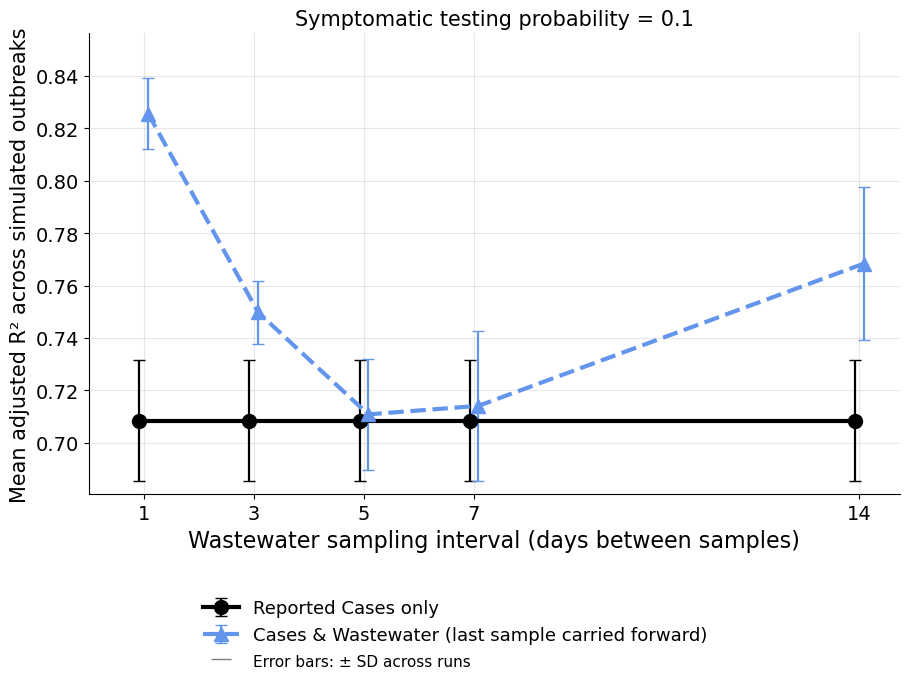

In [49]:
WIN_COLOUR = {1: "cornflowerblue", 3: "#08306b"}
WIN_LABEL = {1: "Cases & Wastewater (last sample carried forward)",
             3: "Cases & Wastewater (trailing average, last 3 samples)"}

def plot_window(win):
    """One figure for one moving-average window: cases only vs cases & wastewater, by sampling interval."""
    lo = min((sampling["mean_cases"] - sampling["sd_cases"]).min(), (sampling["mean_both"] - sampling["sd_both"]).min())
    hi = max((sampling["mean_cases"] + sampling["sd_cases"]).max(), (sampling["mean_both"] + sampling["sd_both"]).max())
    pad = 0.03 * (hi - lo)                                      # same y range for every window, so the plots compare directly

    fig, axes = plt.subplots(1, len(SAMPLING_SYMP_PROBS), figsize=(9.2 * len(SAMPLING_SYMP_PROBS), 6.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sp in zip(axes, SAMPLING_SYMP_PROBS):
        sub = sampling[np.isclose(sampling["value"].astype(float), sp)]
        daily = sub[sub["every"] == 1].iloc[0]
        s = pd.concat([sub[(sub["window"] == win) & (sub["every"] > 1)], pd.DataFrame([daily])]).sort_values("every")
        ax.errorbar(s["every"] - 0.08, s["mean_cases"], yerr=s["sd_cases"], color="black", marker="o", lw=3, ms=10,
                    capsize=4, elinewidth=1.6, label="Reported Cases only", clip_on=False)
        ax.errorbar(s["every"] + 0.08, s["mean_both"], yerr=s["sd_both"], color=WIN_COLOUR.get(win, "gray"), marker="^",
                    ls="--", lw=3, ms=10, capsize=4, elinewidth=1.6, label=WIN_LABEL.get(win, f"window {win}"), clip_on=False)
        ax.set_xticks(sorted(SAMPLING_EVERY)); ax.set_xlim(left=0); ax.set_ylim(lo - pad, hi + pad)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(alpha=0.3)
        ax.set_title(f"Symptomatic testing probability = {sp}", fontsize=15)
        ax.set_xlabel("Wastewater sampling interval (days between samples)", fontsize=16)
        ax.set_ylabel("Mean adjusted R\u00b2 across simulated outbreaks", fontsize=15)
        ax.tick_params(labelsize=14)
    handles, _ = axes[0].get_legend_handles_labels()
    handles.append(Line2D([0], [0], color="gray", marker="_", ls="none", markersize=14, label="Error bars: \u00b1 SD across runs"))
    leg = fig.legend(handles=handles, loc="lower center", ncol=1, fontsize=13, frameon=False)
    leg.get_texts()[-1].set_fontsize(11)
    fig.tight_layout(rect=[0, 0.17, 1, 1])
    fig.savefig(OUT_DIR / f"adjR2_vs_wastewater_sampling_window{win}_{MODEL}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_window(1)      # window of 1 sample: each day uses the last sample carried forward

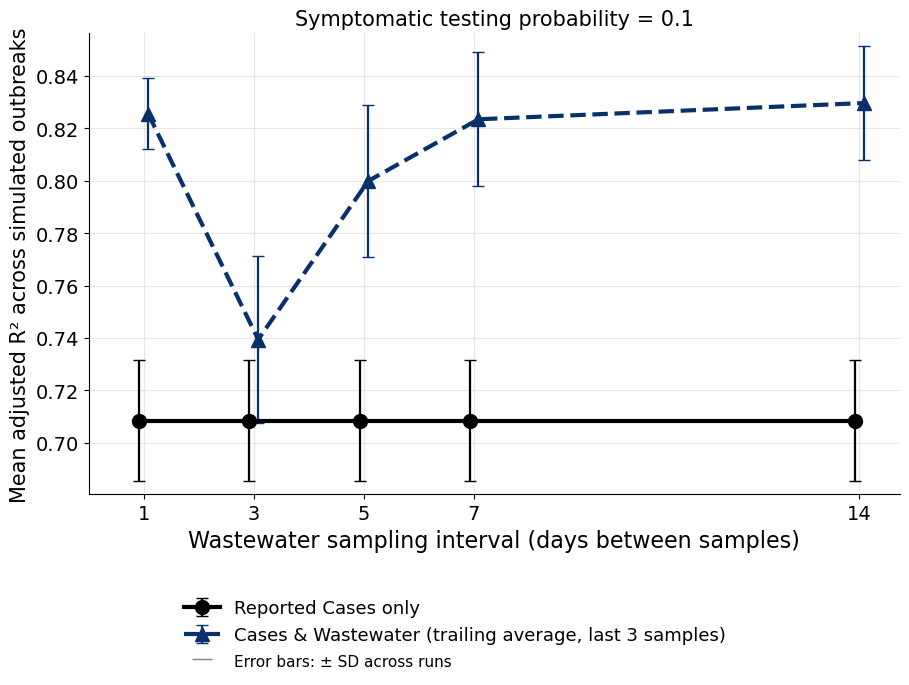

In [50]:
plot_window(3)      # window of 3 samples: each day uses the average of the last 3 samples

## Regression Inspection

In [51]:
# ---- which run and which sampling schemes to look at ----
RUN, SP = 0, 0.10
SETTINGS = [("daily",                   1, 1),
            ("every 3 d, last sample",  3, 1),
            ("every 7 d, last sample",  7, 1),
            ("every 7 d, avg of 3",     7, 3),
            ("every 14 d, last sample", 14, 1),
            ("every 14 d, avg of 3",    14, 3)]
DETAIL = "every 7 d, avg of 3"        # the one whose full regression output is printed

d0 = next(g for g in groups if np.isclose(g["value"].iloc[0], SP) and g["run"].iloc[0] == RUN)

def fit_three(d):
    X = d[["burden", "cases", "wastewater"]]
    return (smf.ols("burden ~ cases", data=X).fit(),
            smf.ols("burden ~ wastewater", data=X).fit(),
            smf.ols("burden ~ cases + wastewater", data=X).fit())

# 1) ONE run: compact table across sampling schemes (t = coefficient / standard error inside the "both" model)
rows, fitted = [], {}
for label, every, win in SETTINGS:
    d = thin_wastewater(d0, every, win, offset=0)
    mc, mw, mb = fit_three(d)
    fitted[label] = mb
    rows.append({"setting": label, "days": int(mb.nobs),
                 "adjR2 cases": mc.rsquared_adj, "adjR2 wastewater": mw.rsquared_adj, "adjR2 both": mb.rsquared_adj,
                 "t cases (in both)": mb.tvalues["cases"], "t wastewater (in both)": mb.tvalues["wastewater"],
                 "corr(cases, wastewater)": d["cases"].corr(d["wastewater"])})
print(f"ONE RUN (run {RUN}, testing probability {SP})")
display(pd.DataFrame(rows).round(3))

# 2) the full regression output for one scheme
print(f"\nFull regression output, 'both' model, {DETAIL}")
print(fitted[DETAIL].summary())

# 3) the same table averaged over ALL runs at this testing level (one run can be atypical)
rng2 = np.random.default_rng(1)
avg = []
for label, every, win in SETTINGS:
    recs = []
    for g in groups:
        if not np.isclose(g["value"].iloc[0], SP) or g["burden"].sum() < FIZZLE_THRESHOLD:
            continue
        d = thin_wastewater(g, every, win, offset=int(rng2.integers(0, every)))
        mc, mw, mb = fit_three(d)
        recs.append(dict(c=mc.rsquared_adj, w=mw.rsquared_adj, b=mb.rsquared_adj,
                         tc=mb.tvalues["cases"], tw=mb.tvalues["wastewater"],
                         cw_neg=mb.params["wastewater"] < 0, cc_neg=mb.params["cases"] < 0,
                         corr=d["cases"].corr(d["wastewater"])))
    r = pd.DataFrame(recs)
    avg.append({"setting": label, "runs": len(r), "adjR2 cases": r.c.mean(), "adjR2 wastewater": r.w.mean(), "adjR2 both": r.b.mean(),
                "mean t cases": r.tc.mean(), "mean t wastewater": r.tw.mean(),
                "% runs wastewater coef < 0": 100 * r.cw_neg.mean(), "% runs cases coef < 0": 100 * r.cc_neg.mean(),
                "corr(cases, wastewater)": r["corr"].mean()})
print(f"\nAVERAGED OVER ALL RUNS (testing probability {SP})")
display(pd.DataFrame(avg).round(3))

ONE RUN (run 0, testing probability 0.1)


,setting,days,adjR2 cases,adjR2 wastewater,adjR2 both,t cases (in both),t wastewater (in both),"corr(cases, wastewater)"
0,daily,108,0.725,0.801,0.809,-2.363,6.913,0.976
1,"every 3 d, last sample",108,0.725,0.742,0.741,0.819,2.757,0.979
2,"every 7 d, last sample",108,0.725,0.631,0.739,6.716,-2.586,0.970
3,"every 7 d, avg of 3",108,0.725,0.239,0.853,21.107,-9.673,0.821
4,"every 14 d, last sample",108,0.725,0.420,0.788,13.568,-5.657,0.896
5,"every 14 d, avg of 3",108,0.725,-0.008,0.841,23.795,-8.824,0.408



Full regression output, 'both' model, every 7 d, avg of 3
                            OLS Regression Results                            
Dep. Variable:                 burden   R-squared:                       0.856
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     312.4
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           6.20e-45
Time:                        15:14:05   Log-Likelihood:                -514.88
No. Observations:                 108   AIC:                             1036.
Df Residuals:                     105   BIC:                             1044.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

,setting,runs,adjR2 cases,adjR2 wastewater,adjR2 both,mean t cases,mean t wastewater,% runs wastewater coef < 0,% runs cases coef < 0,"corr(cases, wastewater)"
0,daily,100,0.708,0.804,0.826,-3.664,8.472,0.0,100.0,0.975
1,"every 3 d, last sample",100,0.708,0.749,0.749,-0.341,4.156,0.0,65.0,0.977
2,"every 7 d, last sample",100,0.708,0.626,0.714,5.759,-1.453,91.0,0.0,0.964
3,"every 7 d, avg of 3",100,0.708,0.238,0.824,18.975,-8.470,100.0,0.0,0.818
4,"every 14 d, last sample",100,0.708,0.403,0.767,13.026,-5.277,100.0,0.0,0.889
5,"every 14 d, avg of 3",100,0.708,-0.003,0.831,23.040,-8.857,100.0,0.0,0.418


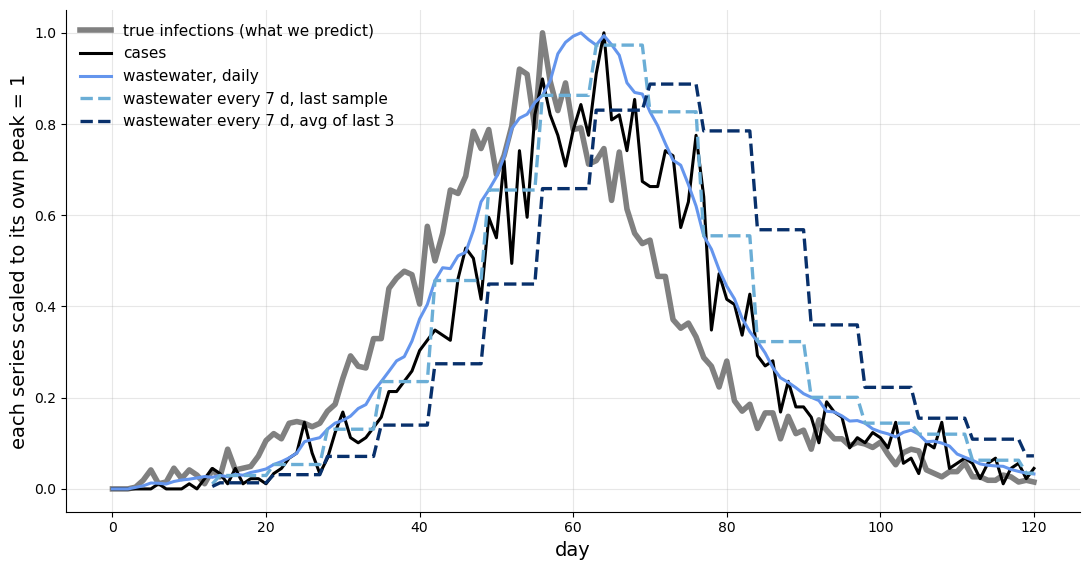

In [52]:
fig, ax = plt.subplots(figsize=(11, 5.8))
base = d0[d0["day"] >= 0]
nrm = lambda x: x / x.max()
ax.plot(base["day"], nrm(base["burden"]), color="gray", lw=4, label="true infections (what we predict)")
ax.plot(base["day"], nrm(base["cases"]), color="black", lw=2.2, label="cases")
ax.plot(base["day"], nrm(base["wastewater"]), color="cornflowerblue", lw=2.2, label="wastewater, daily")
for every, win, col, lab in [(7, 1, "#6baed6", "wastewater every 7 d, last sample"),
                             (7, 3, "#08306b", "wastewater every 7 d, avg of last 3")]:
    t = thin_wastewater(d0, every, win, offset=0)
    ax.plot(t["day"], t["wastewater"] / base["wastewater"].max(), ls="--", lw=2.4, color=col, label=lab)
ax.set_xlabel("day", fontsize=14); ax.set_ylabel("each series scaled to its own peak = 1", fontsize=14)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(alpha=0.3); ax.legend(fontsize=11, frameon=False)
plt.tight_layout(); plt.show()

In [ ]:
from pathlib import Path
print(Path.cwd())                                          # the folder relative paths start from
print(sorted(p.name for p in Path("sensitivity_results").glob("*")) if Path("sensitivity_results").exists() else "no sensitivity_results folder here")

/storage/hcraddock/GitHub/covasim4wastewater/modeling/analysis_sandiego_cases_waste_water
['timeseries_pop10000_delay0.csv']


### Correct Plot

In [53]:
sd_ww = (used.groupby(["value", "window", "every"])["adjr2_wastewater"].std(ddof=1).rename("sd_ww").reset_index())
sampling = sampling.drop(columns=["sd_ww"], errors="ignore").merge(sd_ww, on=["value", "window", "every"])

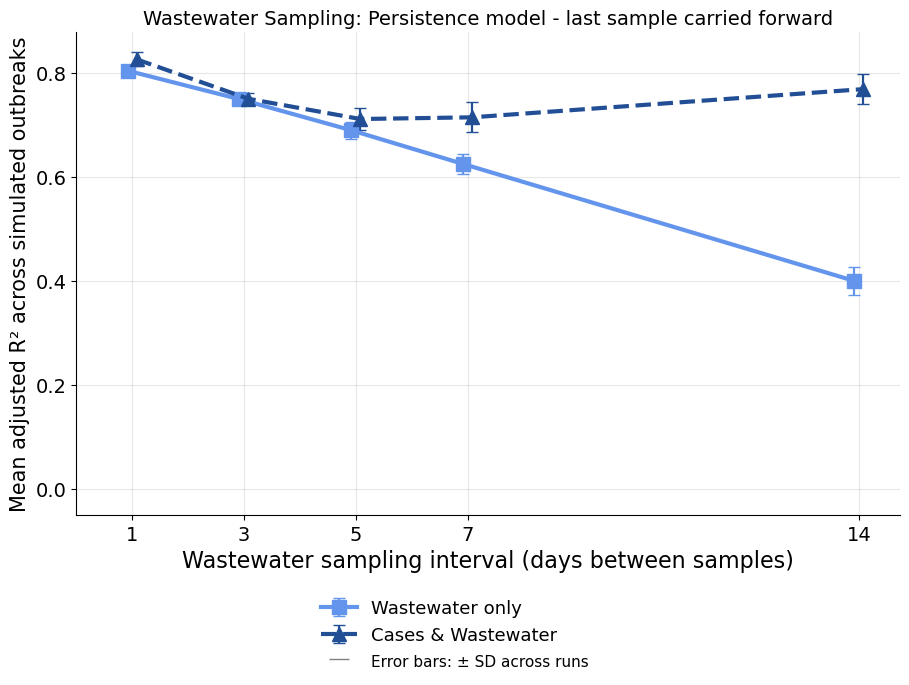

In [88]:
WIN_TITLE = {1: "Persistence model - last sample carried forward", 3: "Moving average of last 3 samples - Right-aligned window"}

def plot_window(win):
    """One figure for one moving-average window: wastewater only vs cases & wastewater, by sampling interval."""
    lo = min((sampling["mean_ww"] - sampling["sd_ww"]).min(), (sampling["mean_both"] - sampling["sd_both"]).min())
    hi = max((sampling["mean_ww"] + sampling["sd_ww"]).max(), (sampling["mean_both"] + sampling["sd_both"]).max())
    pad = 0.03 * (hi - lo)                                      # same y range for every window, so the plots compare directly

    fig, axes = plt.subplots(1, len(SAMPLING_SYMP_PROBS), figsize=(9.2 * len(SAMPLING_SYMP_PROBS), 6.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sp in zip(axes, SAMPLING_SYMP_PROBS):
        sub = sampling[np.isclose(sampling["value"].astype(float), sp)]
        daily = sub[sub["every"] == 1].iloc[0]
        s = pd.concat([sub[(sub["window"] == win) & (sub["every"] > 1)], pd.DataFrame([daily])]).sort_values("every")
        ax.errorbar(s["every"] - 0.08, s["mean_ww"], yerr=s["sd_ww"], color="cornflowerblue", marker="s", lw=3, ms=10,
                    capsize=4, elinewidth=1.6, label="Wastewater only", clip_on=False)
        ax.errorbar(s["every"] + 0.08, s["mean_both"], yerr=s["sd_both"], color=BLUE, marker="^", ls="--", lw=3, ms=10,
                    capsize=4, elinewidth=1.6, label="Cases & Wastewater", clip_on=False)
        ax.set_xticks(sorted(SAMPLING_EVERY)); ax.set_xlim(left=0); ax.set_ylim(lo - pad, hi + pad)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(alpha=0.3)
        #ax.set_title(f"Symptomatic testing probability = {sp}\nwastewater: {WIN_TITLE.get(win, f'window {win}')}", fontsize=14)
        ax.set_title(f"Wastewater Sampling: {WIN_TITLE.get(win, f'window {win}')}", fontsize=14)
        ax.set_xlabel("Wastewater sampling interval (days between samples)", fontsize=16)
        ax.set_ylabel("Mean adjusted R\u00b2 across simulated outbreaks", fontsize=15)
        ax.tick_params(labelsize=14)
    handles, _ = axes[0].get_legend_handles_labels()
    handles.append(Line2D([0], [0], color="gray", marker="_", ls="none", markersize=14, label="Error bars: \u00b1 SD across runs"))
    leg = fig.legend(handles=handles, loc="lower center", ncol=1, fontsize=13, frameon=False)
    leg.get_texts()[-1].set_fontsize(11)
    fig.tight_layout(rect=[0, 0.14, 1, 1])
    fig.savefig(OUT_DIR / f"adjR2_wastewater_vs_both_window{win}_{MODEL}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_window(1)      # window of 1 sample: each day uses the last sample carried forward

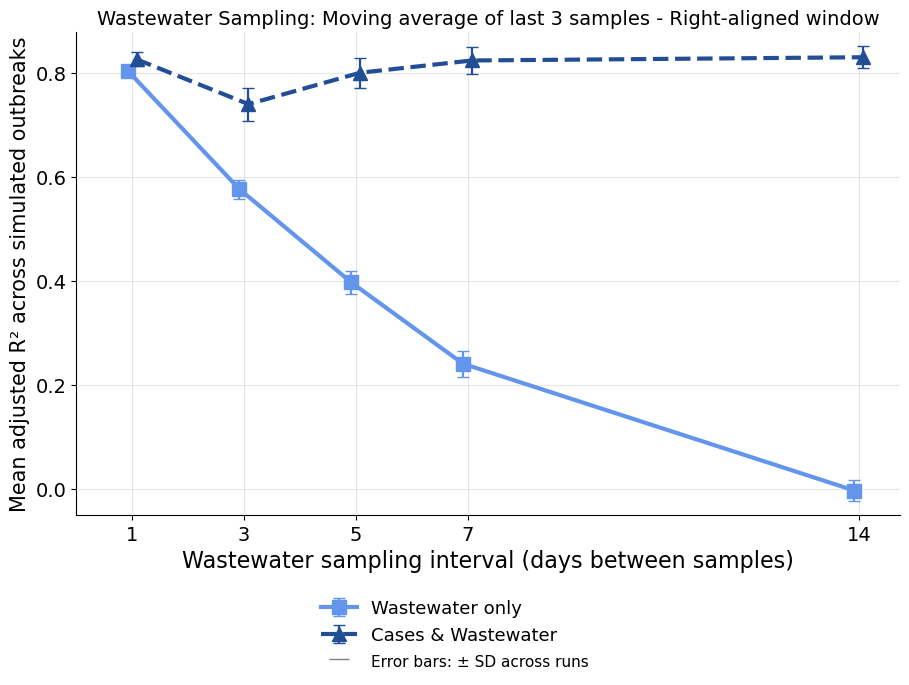

In [80]:
plot_window(3)      # window of 3 samples: each day uses the average of the last 3 samples

In [63]:
PLOT_EVERY = [1, 3, 5, 7]     # sampling intervals shown in the plots (14 is left out; it stays in the saved table)
WIN_TITLE = {1: "Persistence: last sample carried forward",
             3: "Right-aligned moving average of the last 3 samples"}      # keep your own wording here

def plot_window(win):
    shown = sampling[sampling["every"].isin(PLOT_EVERY)]          # only the intervals to display
    lo = min((shown["mean_ww"] - shown["sd_ww"]).min(), (shown["mean_both"] - shown["sd_both"]).min())
    hi = max((shown["mean_ww"] + shown["sd_ww"]).max(), (shown["mean_both"] + shown["sd_both"]).max())
    pad = 0.03 * (hi - lo)
    ...
    for ax, sp in zip(axes, SAMPLING_SYMP_PROBS):
        sub = shown[np.isclose(shown["value"].astype(float), sp)]  # was: sampling[...]
        ...
        ax.set_xticks(sorted(PLOT_EVERY)); ax.set_xlim(left=0); ax.set_ylim(lo - pad, hi + pad)   # was: sorted(SAMPLING_EVERY)

In [65]:
plot_window(1)      # window of 1 sample: each day uses the last sample carried forward

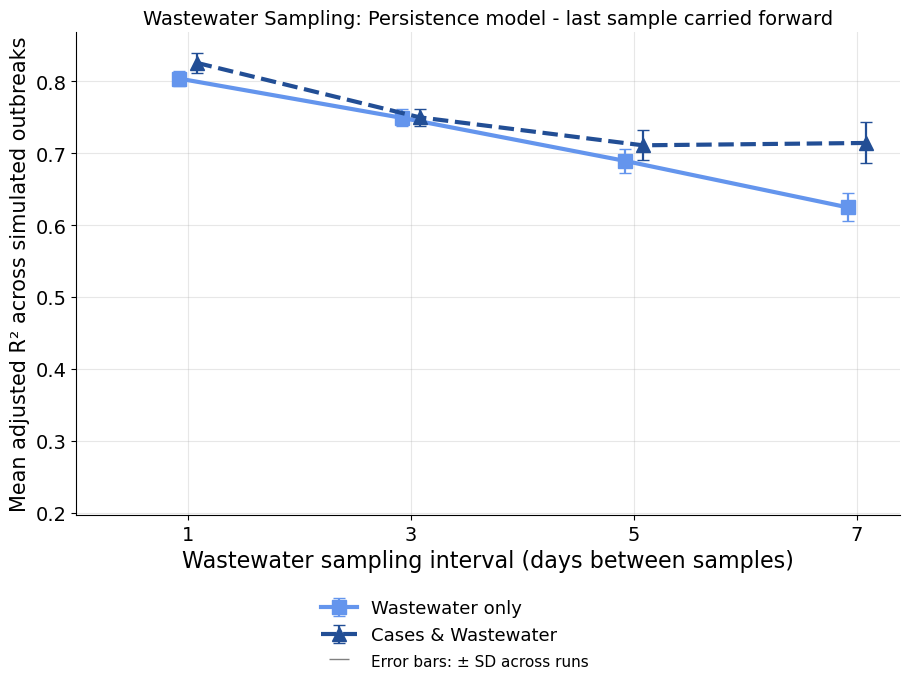

In [92]:
PLOT_EVERY = [1, 3, 5, 7]     # sampling intervals shown in the plots (14 is left out; it stays in the saved table)
WIN_TITLE = {1: "Persistence model - last sample carried forward", 3: "Moving average of last 3 samples - Right-aligned window"}

def plot_window(win):
    """One figure for one moving-average window: wastewater only vs cases & wastewater, by sampling interval."""
    shown = sampling[sampling["every"].isin(PLOT_EVERY)]          # only the intervals to display (1-7 days)
    lo = min((shown["mean_ww"] - shown["sd_ww"]).min(), (shown["mean_both"] - shown["sd_both"]).min())
    hi = max((shown["mean_ww"] + shown["sd_ww"]).max(), (shown["mean_both"] + shown["sd_both"]).max())
    pad = 0.03 * (hi - lo)                                      # same y range for every window, so the plots compare directly

    fig, axes = plt.subplots(1, len(SAMPLING_SYMP_PROBS), figsize=(9.2 * len(SAMPLING_SYMP_PROBS), 6.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sp in zip(axes, SAMPLING_SYMP_PROBS):
        sub = shown[np.isclose(shown["value"].astype(float), sp)]                     # was sampling[...]: this is what let 14 through
        daily = sub[sub["every"] == 1].iloc[0]
        s = pd.concat([sub[(sub["window"] == win) & (sub["every"] > 1)], pd.DataFrame([daily])]).sort_values("every")
        ax.errorbar(s["every"] - 0.08, s["mean_ww"], yerr=s["sd_ww"], color="cornflowerblue", marker="s", lw=3, ms=10,
                    capsize=4, elinewidth=1.6, label="Wastewater only", clip_on=False)
        ax.errorbar(s["every"] + 0.08, s["mean_both"], yerr=s["sd_both"], color=BLUE, marker="^", ls="--", lw=3, ms=10,
                    capsize=4, elinewidth=1.6, label="Cases & Wastewater", clip_on=False)
        ax.set_xticks(sorted(PLOT_EVERY)); ax.set_xlim(left=0); ax.set_ylim(lo - pad, hi + pad)    # was sorted(SAMPLING_EVERY)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(alpha=0.3)
        ax.set_title(f"Wastewater Sampling: {WIN_TITLE.get(win, f'window {win}')}", fontsize=14)
        ax.set_xlabel("Wastewater sampling interval (days between samples)", fontsize=16)
        ax.set_ylabel("Mean adjusted R\u00b2 across simulated outbreaks", fontsize=15)
        ax.tick_params(labelsize=14)
    handles, _ = axes[0].get_legend_handles_labels()
    handles.append(Line2D([0], [0], color="gray", marker="_", ls="none", markersize=14, label="Error bars: \u00b1 SD across runs"))
    leg = fig.legend(handles=handles, loc="lower center", ncol=1, fontsize=13, frameon=False)
    leg.get_texts()[-1].set_fontsize(11)
    fig.tight_layout(rect=[0, 0.14, 1, 1])
    fig.savefig(OUT_DIR / f"adjR2_wastewater_vs_both_window{win}_{MODEL}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_window(1)      # window of 1 sample: each day uses the last sample carried forward

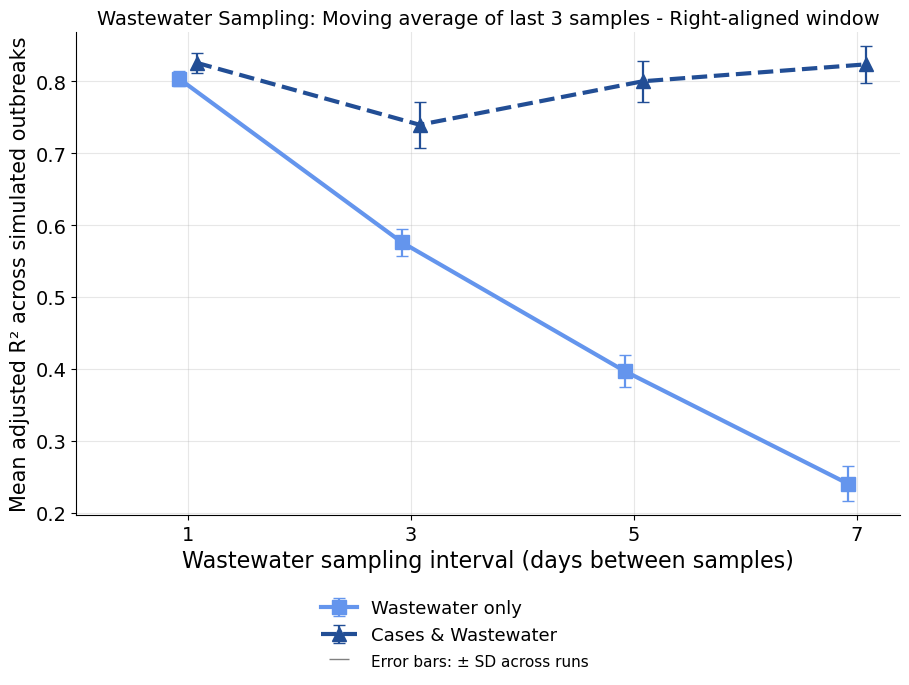

In [90]:
plot_window(3) 

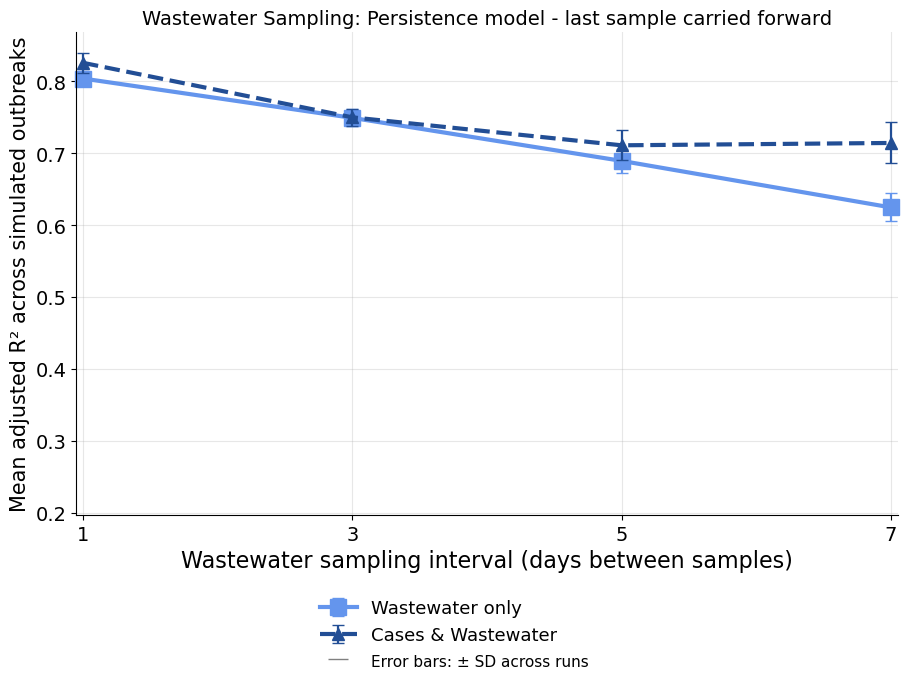

In [103]:
from matplotlib.lines import Line2D

BOTH_COLOUR = "#224e95"       # colour of the "Cases & Wastewater" line
PLOT_EVERY = [1, 3, 5, 7]     # sampling intervals shown (14 is left out; it stays in the saved table)
WIN_TITLE = {1: "Persistence model - last sample carried forward", 3: "Moving average of last 3 samples - Right-aligned window"}

def plot_window(win):
    """One figure for one moving-average window: wastewater only vs cases & wastewater, by sampling interval."""
    shown = sampling[sampling["every"].isin(PLOT_EVERY)]          # only the intervals to display (1-7 days)
    lo = min((shown["mean_ww"] - shown["sd_ww"]).min(), (shown["mean_both"] - shown["sd_both"]).min())
    hi = max((shown["mean_ww"] + shown["sd_ww"]).max(), (shown["mean_both"] + shown["sd_both"]).max())
    pad = 0.03 * (hi - lo)                                        # same y range for every window, so the plots compare directly

    fig, axes = plt.subplots(1, len(SAMPLING_SYMP_PROBS), figsize=(9.2 * len(SAMPLING_SYMP_PROBS), 6.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sp in zip(axes, SAMPLING_SYMP_PROBS):
        sub = shown[np.isclose(shown["value"].astype(float), sp)]
        daily = sub[sub["every"] == 1].iloc[0]
        s = pd.concat([sub[(sub["window"] == win) & (sub["every"] > 1)], pd.DataFrame([daily])]).sort_values("every")

        # no sideways nudge: every point sits at its true interval (1, 3, 5, 7)
        ax.errorbar(s["every"], s["mean_ww"], yerr=s["sd_ww"], color="cornflowerblue", marker="s", lw=3, ms=12,
                    capsize=4, elinewidth=1.6, label="Wastewater only", clip_on=False, zorder=2)
        ax.errorbar(s["every"], s["mean_both"], yerr=s["sd_both"], color=BOTH_COLOUR, marker="^", ls="--", lw=3, ms=9,
                    capsize=4, elinewidth=1.6, label="Cases & Wastewater", clip_on=False, zorder=3)   # drawn on top
        X_PAD = 0.05
        ax.set_xticks(sorted(PLOT_EVERY)); ax.set_xlim(min(PLOT_EVERY) - X_PAD, max(PLOT_EVERY) + X_PAD); ax.set_ylim(lo - pad, hi + pad)
        #ax.set_xticks(sorted(PLOT_EVERY)); ax.set_xlim(min(PLOT_EVERY), max(PLOT_EVERY)); ax.set_ylim(lo - pad, hi + pad)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(alpha=0.3)
        ax.set_title(f"Wastewater Sampling: {WIN_TITLE.get(win, f'window {win}')}", fontsize=14)
        ax.set_xlabel("Wastewater sampling interval (days between samples)", fontsize=16)
        ax.set_ylabel("Mean adjusted R\u00b2 across simulated outbreaks", fontsize=15)
        ax.tick_params(labelsize=14)

    handles, _ = axes[0].get_legend_handles_labels()
    handles.append(Line2D([0], [0], color="gray", marker="_", ls="none", markersize=14, label="Error bars: \u00b1 SD across runs"))
    leg = fig.legend(handles=handles, loc="lower center", ncol=1, fontsize=13, frameon=False)
    leg.get_texts()[-1].set_fontsize(11)
    fig.tight_layout(rect=[0, 0.14, 1, 1])
    fig.savefig(OUT_DIR / f"adjR2_wastewater_vs_both_window{win}_{MODEL}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_window(1)      # window of 1 sample: each day uses the last sample carried forward

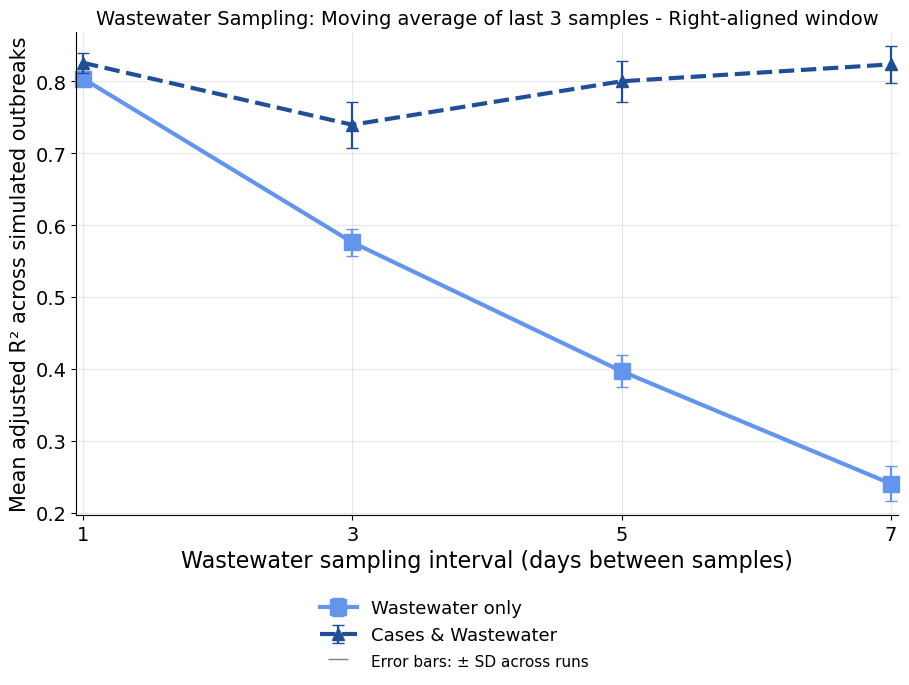

In [104]:
plot_window(3)  